# Heatwave Analysis of Indian Cities (2014 - 2025)

## Part 1: Data Cleaning and Exploratory Analysis | Part 2: Feature Engineering and Forecasting Models | Part 3: Financial Impact

**Business question:** As heatwaves intensify, how much does peak electricity demand rise, how well can we forecast it, and what is the financial cost of getting that forecast wrong?

**Part 1** audits the raw data, applies documented cleaning rules, builds the modeling target, and explores how temperature drives demand. **Part 2** builds leakage-free features, compares baselines against Ridge, Random Forest, Gradient Boosting and a neural network on a time-based split, and tests whether weather actually improves the forecast. **Part 3** converts forecast errors and a heatwave scenario into financial impact, using stated price assumptions.

**Data:** daily state-level peak demand met and unmet (MW) plus weather (tmax, tmin, humidity, heat index) for 28 Indian states, Jan 2014 to Apr 2024. Add the source and license of your file in the README.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb

sb.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

DATA_PATH = Path("../data/final_dataset.csv")
PROCESSED_DIR = Path("../data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load and audit the raw data

In [2]:
raw_data = pd.read_csv(DATA_PATH, parse_dates = ["date"])

print(f"Rows: {len(raw_data):,} | States: {raw_data['state'].nunique()} | "
     f"Dates: {raw_data['date'].min().date()} to {raw_data['date'].max().date()}")
raw_data.head()
raw_data.dtypes

Rows: 105,980 | States: 28 | Dates: 2014-01-08 to 2024-04-28


date             datetime64[us]
state                       str
tmax                    float64
tmin                    float64
humidity                float64
heat_index              float64
hot_day                   int64
hot_night                 int64
peak_met_mw             float64
peak_unmet_mw           float64
dtype: object

## 2. Checking for missing values

In [3]:
full_calendar = pd.date_range(raw_data["date"].min(), raw_data["date"].max(), freq="D")
dup_mask = raw_data.duplicated(["state", "date"], keep=False)
exact_dup = raw_data.duplicated(keep=False)

audit = pd.Series({
    "duplicate state rows(extra copies)": int(raw_data.duplicated(['state', 'date']). sum()),
    "rows in conflicting duplicate groups": int((dup_mask & ~exact_dup).sum()),
    "calendar days missing (all states)": int(len(full_calendar) - raw_data['date'].nunique()),
    "missing peak_met_mw": int(raw_data['peak_met_mw'].isna().sum()),
    "missing peak_unmet_mw": int(raw_data['peak_unmet_mw'].isna().sum()),
    "zero peak_met_mw": int((raw_data['peak_met_mw'] == 0).sum()),
    "negative peak_unmet_mw": int((raw_data['peak_unmet_mw'] < 0).sum()),
    "share of days with zero unmet demand": round(float((raw_data['peak_unmet_mw'] == 0).mean()), 3)
})

audit.to_frame("count / value")
# print(full_calendar)
# print(dup_mask)
# print(exact_dup)


,count / value
duplicate state rows(extra copies),4368.000
rows in conflicting duplicate groups,248.000
calendar days missing (all states),135.000
missing peak_met_mw,160.000
missing peak_unmet_mw,175.000
zero peak_met_mw,3.000
negative peak_unmet_mw,66.000
share of days with zero unmet demand,0.734


In [4]:
WEATHER_COLS = ["tmax", "tmin", "humidity", "heat_index"]
INTERP_LIMIT = 3

# 1. De-duplicate
agg = {c: "first" for c in WEATHER_COLS + ["hot_day", "hot_night"]}
agg.update({"peak_met_mw": "max", "peak_unmet_mw": "max"})
df = raw_data.groupby(['state', 'date'], as_index = False).agg(agg)

#print(df["state"].nunique(), df["state"].isin(["ANDHRA PRADESH", "TELANGANA"]).sum())

# 2. Re-index to a complete daily calendar per state
idx = pd.MultiIndex.from_product([sorted(df['state']. unique()), full_calendar], names = ['state', 'date'])
df = df.set_index(['state', 'date']).reindex(idx).reset_index()

#print(df["state"].nunique(), df["state"].isin(["ANDHRA PRADESH", "TELANGANA"]).sum())


# # 3. Fixing bad values
df.loc[df['peak_met_mw'] <= 0, 'peak_met_mw'] = np.nan
df.loc[df['peak_unmet_mw'] < 0, 'peak_unmet_mw'] = 0

#print(df["state"].nunique(), df["state"].isin(["ANDHRA PRADESH", "TELANGANA"]).sum())


# # 4. Interpolate short gaps only: gaps of up to 3 days are filled, longer gaps stay missing.
# #    (pandas limit = 3 will fill the first 3 days of a long gap; the longer gaps beyond this will be masked to NaN)

def fill_short_gaps(s, max_gap = INTERP_LIMIT):
    isna = s.isna()
    run_id = isna.ne(isna.shift()).cumsum()
    run_len = isna.groupby(run_id).transform("sum")
    filled = s.interpolate(limit_area = "inside")
    return filled.mask(isna & (run_len > max_gap))

num_cols = WEATHER_COLS + ['peak_met_mw', 'peak_unmet_mw']
df = df.sort_values(['state', 'date'])

#print(df["state"].nunique(), df["state"].isin(["ANDHRA PRADESH", "TELANGANA"]).sum())


for c in num_cols:
    df[c] = df.groupby('state')[c].transform(fill_short_gaps)
    
#print(df["state"].nunique(), df["state"].isin(["ANDHRA PRADESH", "TELANGANA"]).sum())

    
# 5. Re-compute heat flags from definitions
# Assumption: A day is considered hot if the max temp is GREATER than 40 degrees.
#             A night is considered hot if the min temp is GREATER than 30 degrees.

df['hot_day'] = (df['tmax'] >= 40).astype(int)
df['hot_night'] = (df['tmin'] >= 30).astype(int)

# # 6. Build the target and drop rows which can't be used
df['peak_demand_mw'] = df['peak_met_mw'] + df['peak_unmet_mw'].fillna(0)
split_noise = df['state'].isin(["ANDHRA PRADESH", "TELANGANA"]) & (df['date'] < "2015-01-01")
df = df[~split_noise].dropna(subset = ['peak_met_mw'] + WEATHER_COLS).reset_index(drop = True)

print(df["state"].nunique(), df["state"].isin(["ANDHRA PRADESH", "TELANGANA"]).sum())

assert df[num_cols].isna().sum().sum() == 0
assert not df.duplicated(['state', 'date']).any()
print(f"Clean rows: {len(df):,} (from {len(raw_data):,}) raw")

28 6720
Clean rows: 103,388 (from 105,980) raw


In [5]:
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month

# Demand relative to each state's own 1-year rolling level: removes the growth trend
# so that seasonal and temperature effects are comparable across states and years.

df['demand_level'] = df.groupby('state')['peak_demand_mw'].transform(
lambda s: s.rolling(365, center = True, min_periods = 180).mean())
df['demand_ratio'] = df['peak_demand_mw'] / df['demand_level']

df.to_csv(PROCESSED_DIR / "clean_daily.csv", index = False)
df.describe().T[['count', 'mean', 'min', 'max']].round(2)


,count,mean,min,max
date,103388,2019-03-15 17:33:12.974039,2014-01-08 00:00:00,2024-04-28 00:00:00
tmax,103388.0,29.242783,-3.46,48.77
tmin,103388.0,19.017853,-14.39,35.93
humidity,103388.0,66.808949,5.32,100.0
heat_index,103388.0,35.706321,15.091401,84.619769
hot_day,103388.0,0.059127,0.0,1.0
hot_night,103388.0,0.008782,0.0,1.0
peak_met_mw,103388.0,5685.543459,21.0,28969.0
peak_unmet_mw,103388.0,45.983784,0.0,6120.0
peak_demand_mw,103388.0,5731.527244,21.0,30982.0


## 3. Exploratory Analysis

### 3.1 Steady growth in demand
Sum of state daily peaks is used as a proxy for national load (state peaks do not occur at the same time, so this is not the official national peak).

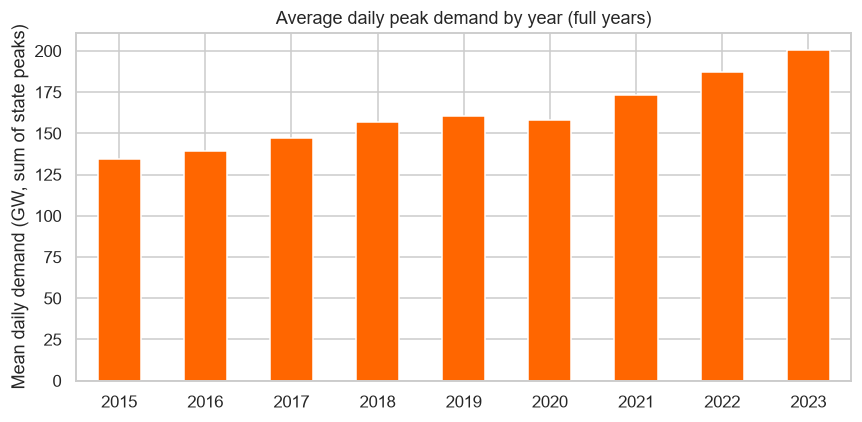

Growth 2015 to 2023:  49%


In [6]:
national = df.groupby('date')['peak_demand_mw'].sum().rename('total_mw').reset_index()
national['year'] = national['date'].dt.year
annual = national.groupby('year')['total_mw'].mean() / 1000
annual = annual.loc[2015:2023] #full years only (2014 lacks AP/Telangana, 2024 is partial)
# national.head(40)
# national.tail(40)
fig, ax = plt.subplots(figsize = (8,4))
annual.plot(kind = "bar", ax = ax, color = "#ff6600")
ax.set_ylabel("Mean daily demand (GW, sum of state peaks)")
ax.set_xlabel("")
ax.set_title("Average daily peak demand by year (full years)")
plt.xticks(rotation = 0)
plt.tight_layout()
plt.show()
print(f"Growth {annual.index[0]} to {annual.index[-1]}: {annual.iloc[-1] / annual.iloc[0] - 1: .0%}")

### 3.2 Temperature & Demand
Demand ratio (relative to the state's own level) against daily max temperature, for the six largest states.

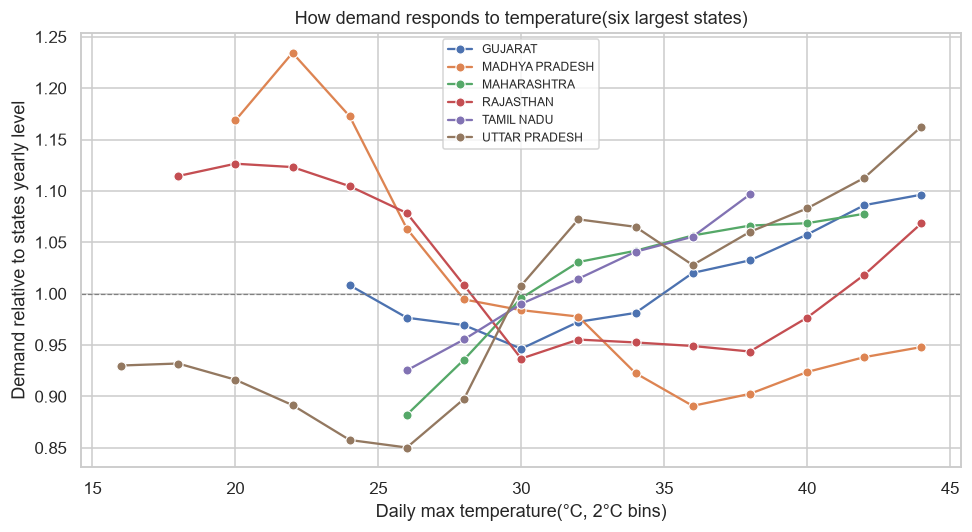

In [7]:
top_states = df.groupby('state')['peak_demand_mw'].mean().nlargest(6).index
sub = df[df['state'].isin(top_states)].copy()
sub['tmax_bin'] = (sub['tmax'] // 2*2).clip(lower = 14, upper = 44)

binned = (sub.groupby(['state', 'tmax_bin'])['demand_ratio']
         .agg(['mean', 'count']).reset_index())
binned = binned[binned['count'] >= 20]

fig, ax = plt.subplots(figsize = (9, 5))
sb.lineplot(data = binned, x = 'tmax_bin', y = 'mean', hue = 'state', marker = 'o', ax = ax)
ax.axhline(1, color = 'grey', lw = 0.8, ls = '--')
ax.set_xlabel("Daily max temperature(°C, 2°C bins)")
ax.set_ylabel("Demand relative to states yearly level")
ax.set_title("How demand responds to temperature(six largest states)")
ax.legend(title = "", fontsize = 8)
plt.tight_layout()
plt.savefig("../images/temperature_response.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.3 Seasonality: Finding which months are the demand peaks.

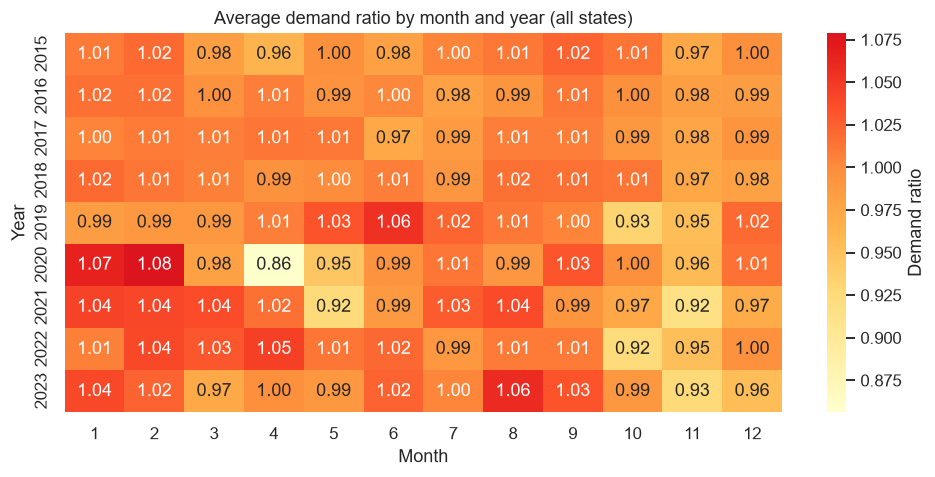

In [8]:
nat_ratio = (df.groupby(['year', 'month'])['demand_ratio'].mean().unstack('month'))
nat_ratio = nat_ratio.loc[2015:2023]

fig, ax = plt.subplots(figsize = (9, 4.5))
sb.heatmap(nat_ratio, cmap = "YlOrRd", center = 1, annot = True, fmt = ".2f", cbar_kws = {"label": "Demand ratio"}, ax = ax)
ax.set_xlabel("Month")
ax.set_ylabel("Year")
ax.set_title("Average demand ratio by month and year (all states)")
plt.tight_layout()
plt.show()

The most visible feature is the April 2020 dip (ratio about 0.86), which lines up with the COVID-19 lockdown. Treat 2020 as an unusual year in the modeling and test results with and without it.

### 3.4 Determining whether hot days affect the demand

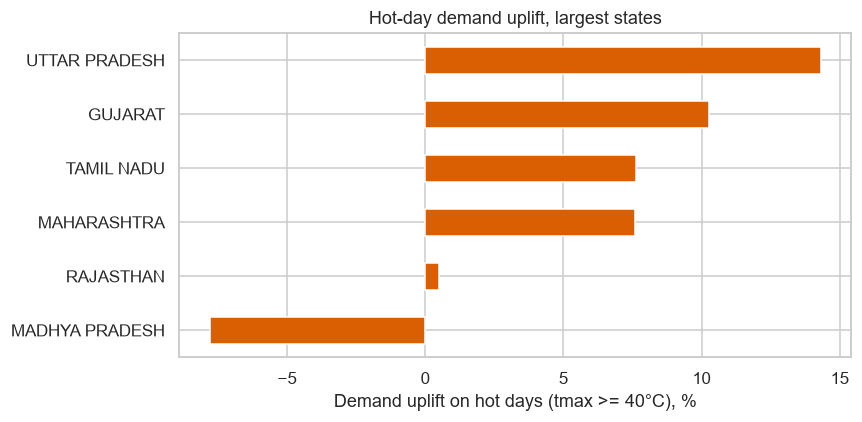

,normal_day,hot_day,uplift_pct
state,,,
GUJARAT,0.979,1.080,10.264
MADHYA PRADESH,1.012,0.933,-7.790
MAHARASHTRA,0.995,1.071,7.586
RAJASTHAN,1.000,1.005,0.519
TAMIL NADU,1.000,1.077,7.624
UTTAR PRADESH,0.975,1.114,14.319


In [9]:
effect = (df[df['state'].isin(top_states)]
          .groupby(['state', 'hot_day'])['demand_ratio'].mean().unstack('hot_day'))
effect.columns = ['normal_day', 'hot_day']
effect['uplift_pct'] = (effect['hot_day'] / effect['normal_day'] - 1) * 100

fig, ax = plt.subplots(figsize = (8,4))
effect['uplift_pct'].sort_values().plot(kind = 'barh', ax = ax, color = "#d95f02")
ax.set_xlabel("Demand uplift on hot days (tmax >= 40°C), %")
ax.set_ylabel("")
ax.set_title("Hot-day demand uplift, largest states")
plt.tight_layout()
plt.show()
effect.round(3)

The uplift differs a lot by state and can even be negative for some. Caution: hot days fall mostly in April to June, when demand is already seasonally high, so this raw uplift mixes the heat effect with season. Part 2 separates the two with a model that controls for calendar effects.

### 3.5 Unmet demand

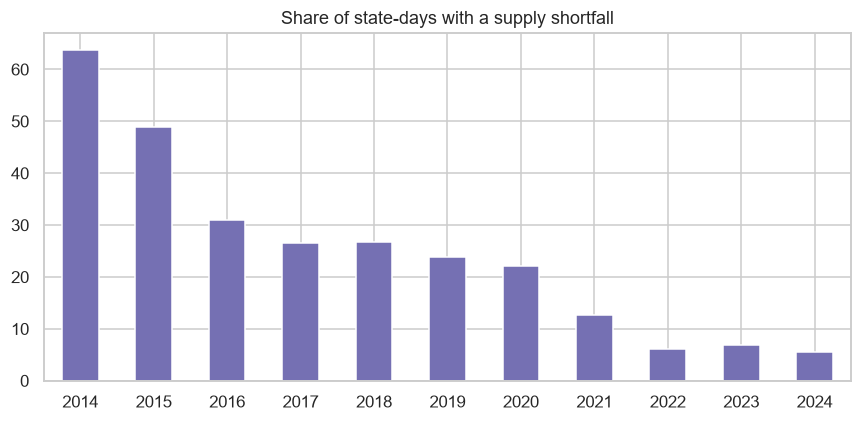

Average daily unmet peak(MW), top 5 states:
state
UTTAR PRADESH    634.0
KARNATAKA        135.0
TAMIL NADU        95.0
ASSAM             63.0
BIHAR             61.0


In [10]:
shortfall = (df.assign(short_day = df['peak_unmet_mw'] > 0)
            .groupby('year')['short_day'].mean() * 100)

fig,ax = plt.subplots(figsize = (8,4))
shortfall.plot(kind = "bar", ax = ax, color = "#7570b3")
ax.set_xlabel("% of state-days with unmet demand")
ax.set_xlabel("")
ax.set_title("Share of state-days with a supply shortfall")
plt.xticks(rotation = 0)
plt.tight_layout()
plt.show()

top_unmet = df.groupby('state')['peak_unmet_mw'].mean().nlargest(5).round(0)
print("Average daily unmet peak(MW), top 5 states:")
print(top_unmet.to_string())

## Takeaways from Part 1
**Demand growth:** Average daily peak demand (the sum of state peaks, a proxy for national load) grew about 49% between 2015 and 2023, from roughly 135 GW to 201 GW, or about 5.1% a year. Growth was uneven: it reached 6.6% in 2018, slowed to 2.1% in 2019 and turned slightly negative in 2020 (-1.2%, the COVID-19 lockdown year). The steepest rise came in 2021 (+9.4%) as demand rebounded, followed by +8.2% in 2022 and +7.1% in 2023.

# Part 2: Feature Engineering and Forecasting Models
**Task:** predict a state's peak electricity demand on day *t* using only information that would be known at that time:
- demand history up to day *t-1* (lags and rolling averages),
- calendar facts about day *t*,
- weather on day *t* (in practice this would be a weather *forecast*, see limitations at the end).

**Leakage rule:** nothing in the feature set may use demand from day *t* or later. This is why Part 2 does **not** use the centered `demand_level` and `demand_ratio` from Part 1, which look into the future.

**Handling the growth trend:** demand grows every year and tree models cannot extrapolate beyond what they saw. So each state's demand is divided by its own *backward-looking* 365-day average (`base`), the model predicts that ratio, and the prediction is multiplied back by `base` to get MW.

**Split:** train up to 2021, validate on 2022, test from 2023 onward. Splitting by time (never randomly) mirrors real forecasting.

In [11]:
import itertools

from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.linear_model import Ridge
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
TRAIN_END = "2021-12-31"
VAL_END = "2022-12-31"
LOCKDOWN = ("2020-03-25", "2020-06-30")
EXCLUDE_LOCKDOWN = True

## 4. Building the Modeling Table

### 4.1 A complete daily panel
Lag features are shifts by *rows*, so every state must have one row per calendar day. We reload the cleaned file and reindex again; days that Part 1 removed come back as NaN and are excluded later.

In [12]:
clean = pd.read_csv(PROCESSED_DIR / "clean_daily.csv", parse_dates = ["date"])
panel = clean[['state', 'date', 'peak_demand_mw', 'tmax', 'tmin', 'humidity', 'heat_index']]

all_days = pd.date_range(panel['date'].min(), panel['date'].max(), freq = "D")
idx = pd.MultiIndex.from_product([sorted(panel['state'].unique()), all_days], names = ['state', 'date'])
panel = (panel.set_index(['state', 'date']).reindex(idx).reset_index()
         .sort_values(['state', 'date']).reset_index(drop = True))

print(panel.shape)

(105392, 7)


### 4.2 Backward-looking demand features
- `lag_1`, `lag_7`, `lag_14`: demand 1, 7 and 14 days earlier.
- `roll_7`, `roll_30`: average of the *previous* 7 / 30 days. The `shift(1)` before `rolling` is what keeps today's demand out of the window.
- `base`: average of the previous 365 days (needs at least 180 days of history), the state's recent demand level.
- Lags and rolling means are divided by `base`, so they are scale-free and comparable across big and small states. The target `y` is today's demand divided by `base`.

In [13]:
g = panel.groupby('state')['peak_demand_mw']
panel['lag_1'] = g.shift(1)
panel['lag_7'] = g.shift(7)
panel['lag_14'] = g.shift(14)
panel['roll_7'] = g.transform(lambda s: s.shift(1).rolling(7, min_periods = 5).mean())
panel['roll_30'] = g.transform(lambda s: s.shift(1).rolling(30, min_periods = 20).mean())
panel['base'] = g.transform(lambda s: s.shift(1).rolling(365, min_periods = 180).mean())

for c in ['lag_1', 'lag_7', 'lag_14', 'roll_7', 'roll_30']:
    panel[c  + '_r'] = panel[c] / panel['base']

panel['y'] = panel['peak_demand_mw'] / panel['base']
panel['log_base'] = np.log(panel['base'])

In [14]:
   s = panel[panel["state"] == "MAHARASHTRA"].set_index("date")
   d = pd.Timestamp("2022-05-10")
   print(s.loc[d, "lag_1"], s.loc[d - pd.Timedelta(days=1), "peak_demand_mw"])

27287.0 27287.0


### 4.3 Weather and Calendar features
- `tmax_anom`: how much hotter than normal the day is, relative to that state's average `tmax` for the same month. The averages are computed from the **training years only**, otherwise the test period would leak into the features.
- `tmax_roll3`: mean of `tmax` over today and the previous two days (heat builds up).
- `hot_streak`: number of consecutive days with `tmax >= 40`, ending today. This is the heatwave feature.
- Calendar: day-of-year as sine/cosine (so December and January are neighbours), day-of-week dummies, a weekend flag.

In [15]:
panel["month"] = panel["date"].dt.month
clim = (panel[panel["date"] <= TRAIN_END].groupby(["state", "month"])["tmax"]
             .mean().rename("tmax_clim").reset_index())
panel = (panel.merge(clim, on=["state", "month"], how="left")
              .sort_values(["state", "date"]).reset_index(drop=True))
panel["tmax_anom"] = panel["tmax"] - panel["tmax_clim"]
panel["tmax_roll3"] = panel.groupby("state")["tmax"].transform(lambda s: s.rolling(3, min_periods=2).mean())

panel["hot_day"] = (panel["tmax"] >= 40).astype(int)
panel["hot_night"] = (panel["tmin"] >= 30).astype(int)

def streak(b):
    # running count of consecutive 1s: the counter restarts after every 0
    return b.groupby((b == 0).cumsum()).cumsum()

panel["hot_streak"] = panel.groupby("state")["hot_day"].transform(streak)

doy = panel["date"].dt.dayofyear
panel["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
panel["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)
panel["is_weekend"] = (panel["date"].dt.dayofweek >= 5).astype(int)

dow = pd.get_dummies(panel["date"].dt.dayofweek, prefix="dow", drop_first=True).astype(int)
st = pd.get_dummies(panel["state"], prefix="st", drop_first=True).astype(int)
panel = pd.concat([panel, dow, st], axis=1)

WEATHER = ["tmax", "tmin", "humidity", "heat_index", "tmax_anom", "tmax_roll3",
           "hot_day", "hot_night", "hot_streak"]
FEATURES = (["lag_1_r", "lag_7_r", "lag_14_r", "roll_7_r", "roll_30_r", "log_base"]
            + WEATHER + ["doy_sin", "doy_cos", "is_weekend"]
            + list(dow.columns) + list(st.columns))

data = panel.dropna(subset=FEATURES + ["y"]).reset_index(drop=True)
print(f"Modeling rows: {len(data):,} | features: {len(FEATURES)} | first date: {data['date'].min().date()}")

Modeling rows: 95,744 | features: 51 | first date: 2014-07-07


## 5. Time-based split

In [16]:
train = data[data['date'] <= TRAIN_END].reset_index(drop = True)
val = data[(data['date'] > TRAIN_END) & (data['date'] <= VAL_END)].reset_index(drop = True)
test = data[data['date'] > VAL_END].reset_index(drop = True)

assert train['date'].max() < val['date'].min() and val['date'].max() < test['date'].min()
print(f"train {len(train):,} | val {len(val):,} | test {len(test):,}")
print(f"test period: {test['date'].min().date()} to {test['date'].max().date()}")

lockdown_mask = train['date'].between(*LOCKDOWN)
train_fit = train[~lockdown_mask] if EXCLUDE_LOCKDOWN else train
print(f"lockdown rows removed from training: {len(train) -  len(train_fit):,}")

train 71,972 | val 10,220 | test 13,552
test period: 2023-01-01 to 2024-04-28
lockdown rows removed from training: 2,744


## 6. Metrics and Baselines
**Why WAPE?** MAPE averages percentage errors per row, so tiny states with a few hundred MW dominate the score. WAPE (weighted absolute percentage error) is total absolute error divided by total actual demand, so each MW counts equally. MAE and RMSE are in MW.

**Baselines** any model must beat: *persistence* (tomorrow = today, `lag_1`) and *same weekday last week* (`lag_7`).

In [17]:
def wape(actual, pred):
    return float(np.abs(actual - pred).sum() / actual.sum() * 100)

def metrics(d, pred_mw):
    a = d['peak_demand_mw'].values
    return {"MAE_MW": float(np.abs(a - pred_mw).mean()),
           "RMSE_MW": float(np.sqrt(((a - pred_mw) ** 2).mean())),
           "WAPE_%": wape(a, pred_mw)}

rows = []
for name, col in [("Persistence (lag 1)", "lag_1"), ("Same day last week (lag 7)", "lag_7")]:
    rows.append({"model": name, "split": "validation", **metrics(val, val[col].values)})
    rows.append({"model": name, "split": "test", **metrics(test, test[col].values)})

pd.DataFrame(rows).round(2)

,model,split,MAE_MW,RMSE_MW,WAPE_%
0,Persistence (lag 1),validation,249.14,464.47,3.72
1,Persistence (lag 1),test,276.83,590.38,3.81
2,Same day last week (lag 7),validation,453.42,865.84,6.77
3,Same day last week (lag 7),test,521.61,1033.88,7.18


In [18]:
# sample check for comparison
print(test[["state", "date", "peak_demand_mw", "lag_1"]].head())

            state       date  peak_demand_mw    lag_1
0  ANDHRA PRADESH 2023-01-01         10432.0  10268.0
1  ANDHRA PRADESH 2023-01-02         10244.0  10432.0
2  ANDHRA PRADESH 2023-01-03         10475.0  10244.0
3  ANDHRA PRADESH 2023-01-04         10629.0  10475.0
4  ANDHRA PRADESH 2023-01-05         10593.0  10629.0


## 7. Models
All models predict the ratio `y` and are converted back to MW by multiplying with `base`. First we compare them on the **validation** year, and lightly tune the gradient boosting model there.

In [19]:
def make_models():
    return {
        "Ridge": make_pipeline(StandardScaler(), Ridge(alpha = 1.0)),
        "Random Forest": RandomForestRegressor(n_estimators = 100, min_samples_leaf = 10, max_features = 0.5,
                                              n_jobs = -1, random_state = RANDOM_STATE),
        "Gradient Boosting": HistGradientBoostingRegressor(max_iter = 300, learning_rate = 0.5, max_leaf_nodes = 31,
                                                          min_samples_leaf = 40, random_state = RANDOM_STATE),
        "Neural Network (MLP)": make_pipeline(
            StandardScaler(),
            MLPRegressor(hidden_layer_sizes = (64, 32), early_stopping = True, max_iter = 300,
                        n_iter_no_change = 10, random_state = RANDOM_STATE))
    }

val_rows = []
for name, model in make_models().items():
    model.fit(train_fit[FEATURES], train_fit["y"])
    pred = model.predict(val[FEATURES]) * val["base"].values
    val_rows.append({"model": name, **metrics(val, pred)})

pd.DataFrame(val_rows).sort_values("WAPE_%").round(2)

,model,MAE_MW,RMSE_MW,WAPE_%
1,Random Forest,219.89,400.04,3.28
2,Gradient Boosting,223.20,404.90,3.33
3,Neural Network (MLP),228.25,406.79,3.41
0,Ridge,235.69,426.90,3.52


In [20]:
# Mini hyper-parameter search for gradient boosting, scored on the validation year
grid = list(itertools.product([0.03, 0.06],[15, 31],[40, 100])) # learning rate, leaves, min leaf size

search = []
for lr, leaves, msl in grid:
    m = HistGradientBoostingRegressor(max_iter = 300, learning_rate = lr, max_leaf_nodes = leaves,
                                     min_samples_leaf = msl, random_state = RANDOM_STATE)
    m.fit(train_fit[FEATURES], train_fit["y"])
    pred = m.predict(val[FEATURES]) * val["base"].values
    search.append({"learning_rate": lr, "max_leaf_nodes": leaves, "min_samples_leaf": msl,
                  "val_WAPE_%": wape(val["peak_demand_mw"].values, pred)})
search = pd.DataFrame(search).sort_values("val_WAPE_%").reset_index(drop = True)
BEST_GB = search.loc[0, ["learning_rate", "max_leaf_nodes", "min_samples_leaf"]].to_dict()
BEST_GB["max_leaf_nodes"] = int(BEST_GB["max_leaf_nodes"])
BEST_GB["min_samples_leaf"] = int(BEST_GB["min_samples_leaf"])
print("Best settings:", BEST_GB)
search.round(3)

Best settings: {'learning_rate': 0.06, 'max_leaf_nodes': 31, 'min_samples_leaf': 100}


,learning_rate,max_leaf_nodes,min_samples_leaf,val_WAPE_%
0,0.06,31,100,3.126
1,0.06,31,40,3.138
2,0.03,31,100,3.184
3,0.03,31,40,3.191
4,0.06,15,100,3.233
5,0.06,15,40,3.243
6,0.03,15,40,3.308
7,0.03,15,100,3.309


## 8. Final Evaluation on the Test Period
Models are refit on **train + validation** (still excluding the lockdown window) and scored once on the untouched test period (2023 onward). Besides the overall score, we look at two harder slices: the **summer months (April to June)** and **hot days** (`tmax >= 40`), where heatwave forecasting matters most.

In [21]:
train_val = pd.concat([train, val], ignore_index = True)
if EXCLUDE_LOCKDOWN:
    train_val = train_val[~train_val["date"].between(*LOCKDOWN)]

models = make_models()
models["Gradient Boosting"] = HistGradientBoostingRegressor(max_iter = 300, random_state = RANDOM_STATE, **BEST_GB)

preds = {}

for name, model in models.items():
    model.fit(train_val[FEATURES], train_val["y"])
    preds[name] = model.predict(test[FEATURES]) * test ["base"].values
preds["Persistence (lag 1)"] = test["lag_1"].values
preds["Same day last week (lag 7)"] = test["lag_7"].values

actual = test["peak_demand_mw"].values                             # the real demand
summer = test["date"].dt.month.isin([4, 5, 6]).values              # summer season for months: April(4), May(5), and June(5) which is TRUE
hot = (test["hot_day"] == 1).values                                # TRUE for days with tmax of 40 degrees Celsius or more

results = pd.DataFrame([
    {"model": n, **metrics(test, p),
     "WAPE_summer_%": wape(actual[summer], p[summer]),
     "WAPE_hot_days_%": wape(actual[hot], p[hot])}
    for n, p in preds.items()
]).sort_values("WAPE_%").reset_index(drop = True)

print(f"test rows: {len(test):,} | summer rows: {summer.sum():,} | hot-day rows: {hot.sum():,}")
results.round(2)

test rows: 13,552 | summer rows: 3,332 | hot-day rows: 603


,model,MAE_MW,RMSE_MW,WAPE_%,WAPE_summer_%,WAPE_hot_days_%
0,Neural Network (MLP),221.05,468.35,3.04,3.25,2.74
1,Gradient Boosting,230.12,480.12,3.17,3.47,2.91
2,Random Forest,240.37,496.62,3.31,3.63,3.02
3,Ridge,258.22,525.46,3.56,3.80,3.17
4,Persistence (lag 1),276.83,590.38,3.81,4.04,3.30
5,Same day last week (lag 7),521.61,1033.88,7.18,8.48,7.42


In [22]:
# Model's improvement over persistence check:
base_w = results.loc[results["model"] == "Persistence (lag 1)", "WAPE_%"].iloc[0]
results["vs_persistence_%"] = (1 - results["WAPE_%"] / base_w) * 100
results.round(2)

,model,MAE_MW,RMSE_MW,WAPE_%,WAPE_summer_%,WAPE_hot_days_%,vs_persistence_%
0,Neural Network (MLP),221.05,468.35,3.04,3.25,2.74,20.15
1,Gradient Boosting,230.12,480.12,3.17,3.47,2.91,16.87
2,Random Forest,240.37,496.62,3.31,3.63,3.02,13.17
3,Ridge,258.22,525.46,3.56,3.80,3.17,6.72
4,Persistence (lag 1),276.83,590.38,3.81,4.04,3.30,0.00
5,Same day last week (lag 7),521.61,1033.88,7.18,8.48,7.42,-88.43


## 9. Visual Comparison

Best model on test: Neural Network (MLP)


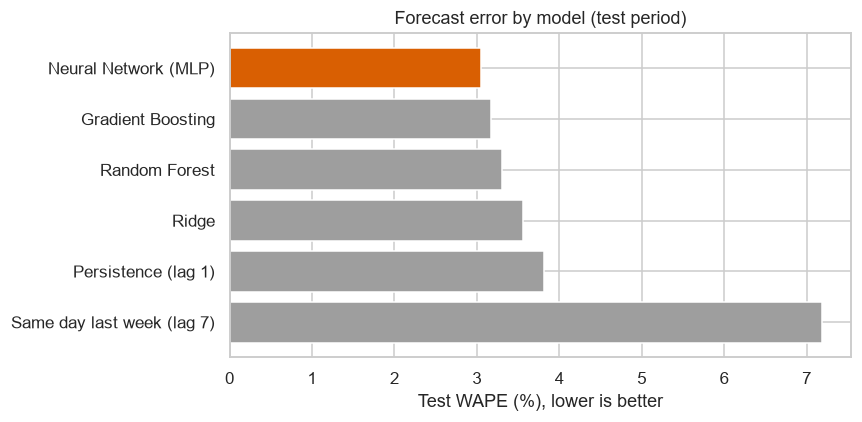

In [23]:
ml_models = [n for n in preds if n not in ("Persistence (lag 1)", "Same day last week (lag 7)")]
best_name = results[results["model"].isin(ml_models)].iloc[0]["model"]
print("Best model on test:", best_name)

fig, ax = plt.subplots(figsize=(8, 4))
colors = ["#d95f02" if m == best_name else "#9e9e9e" for m in results["model"]]
ax.barh(results["model"], results["WAPE_%"], color=colors)
ax.invert_yaxis()
ax.set_xlabel("Test WAPE (%), lower is better")
ax.set_title("Forecast error by model (test period)")
plt.tight_layout()
plt.savefig("../images/model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

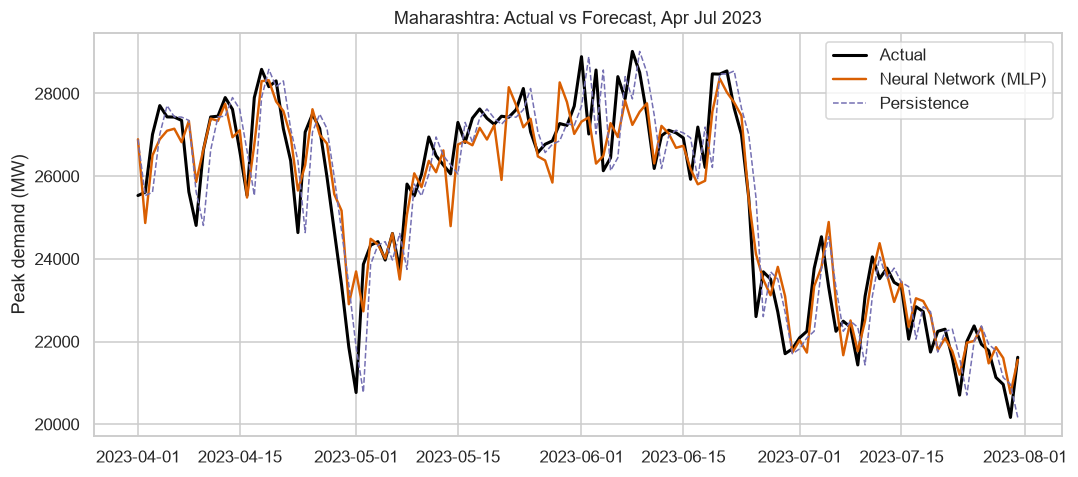

In [24]:
big_state = test.groupby("state")["peak_demand_mw"].mean().idxmax()
mask = ((test["state"] == big_state) & test["date"].between("2023-04-01", "2023-07-31")).values

fix, ax = plt.subplots(figsize = (10, 4.5))
ax.plot(test.loc[mask, "date"], actual[mask], color = "black", lw = 2, label = "Actual")
ax.plot(test.loc[mask, "date"], preds[best_name][mask], color = "#d95f02", lw = 1.6, label = best_name)
ax.plot(test.loc[mask, "date"], preds["Persistence (lag 1)"][mask], color = "#7570b3", lw = 1, ls = "--", label = "Persistence")
ax.set_ylabel("Peak demand (MW)")
ax.set_title(f"{big_state.title()}: Actual vs Forecast, Apr Jul 2023")
ax.legend()
plt.tight_layout()
plt.savefig("../images/actual_vs_forecast.png", dpi=150, bbox_inches="tight")
plt.show()

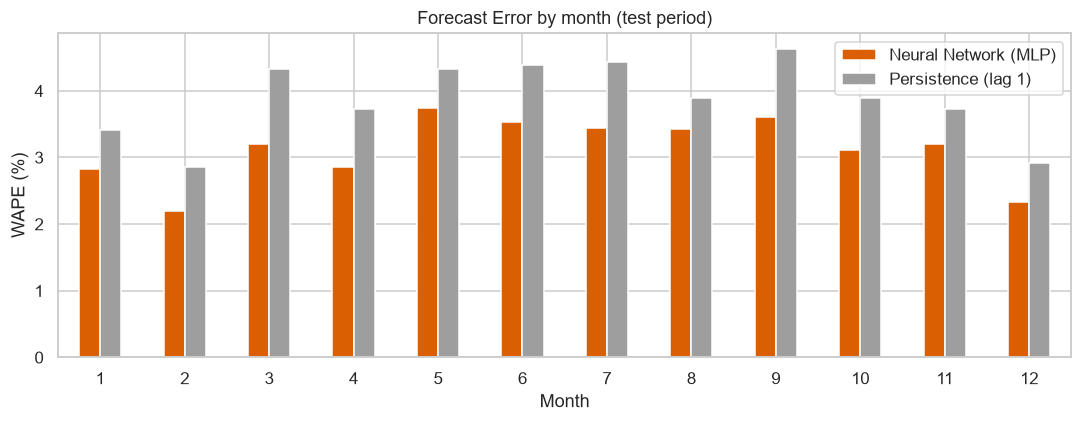

In [25]:
month = test["date"].dt.month.values
by_month = pd.DataFrame({
    "month": sorted(set(month)),
    best_name: [wape(actual[month == m], preds[best_name][month == m]) for m in sorted(set(month))],
    "Persistence (lag 1)": [wape(actual[month == m], preds["Persistence (lag 1)"][month == m]) for m in sorted(set(month))],
}).set_index("month")

ax = by_month.plot(kind = "bar", figsize = (10, 4), color = ["#d95f02","#9e9e9e"])
ax.set_ylabel("WAPE (%)")
ax.set_xlabel("Month")
ax.set_title("Forecast Error by month (test period)")
plt.xticks(rotation = 0)
plt.tight_layout()
plt.show()

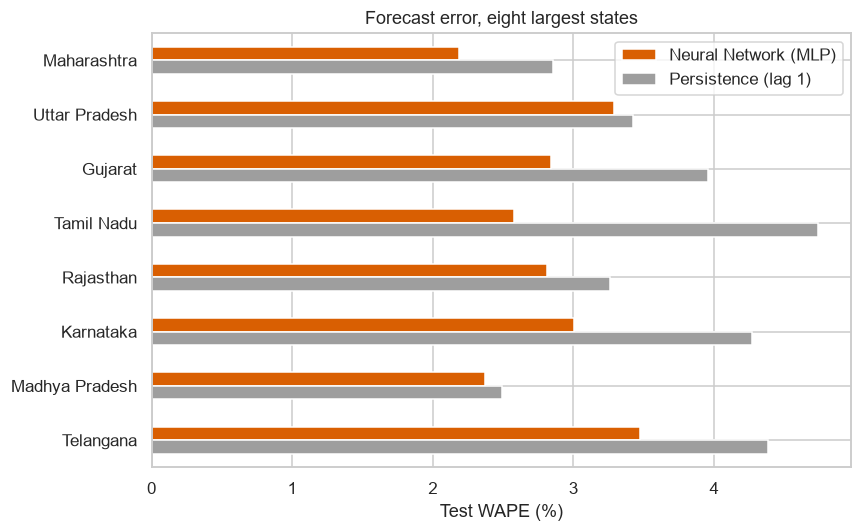

In [26]:
top8 = test.groupby("state")["peak_demand_mw"].mean().nlargest(8).index
rows = []
for s in top8:
    mk = (test["state"] == s).values
    rows.append({"state": s.title(),
                best_name: wape(actual[mk], preds[best_name][mk]),
                "Persistence (lag 1)": wape(actual[mk], preds["Persistence (lag 1)"][mk])})
per_state = pd.DataFrame(rows).set_index("state")

ax = per_state.plot(kind = "barh", figsize = (8, 5), color = ["#d95f02", "#9e9e9e"])
ax.invert_yaxis()
ax.set_xlabel("Test WAPE (%)")
ax.set_ylabel("")
ax.set_title("Forecast error, eight largest states")
plt.tight_layout()
plt.show()

## 10. Does weather actually help?
Train the same gradient boosting model **without** any weather feature and compare. If weather matters, the gap should be largest on summer and hot days.

In [27]:
no_weather = [f for f in FEATURES if f not in WEATHER]
gb_nw = HistGradientBoostingRegressor(max_iter = 300, random_state = RANDOM_STATE, **BEST_GB)
gb_nw.fit(train_val[no_weather], train_val["y"])
p_nw = gb_nw.predict(test[no_weather]) * test["base"].values
p_w = preds["Gradient Boosting"]

ablation = pd.DataFrame({
    "with weather": [wape(actual, p_w), wape(actual[summer], p_w[summer]), wape(actual[hot], p_w[hot])],
    "without weather": [wape(actual, p_nw), wape(actual[summer], p_nw[summer]), wape(actual[hot], p_nw[hot])],
}, index = ["all days", "summer days (Apr to Jun)", "hot days (tmax >= 40)"])
ablation["improvement (pct. points)"] = ablation["without weather"] - ablation["with weather"]
ablation.round(2)

,with weather,without weather,improvement (pct. points)
all days,3.17,3.25,0.08
summer days (Apr to Jun),3.47,3.64,0.17
hot days (tmax >= 40),2.91,3.12,0.21


### Robustness: does excluding Lockdown period matter?

In [28]:
train_val_all = pd.concat([train, val], ignore_index = True)
gb_lock = HistGradientBoostingRegressor(max_iter = 300, random_state = RANDOM_STATE, **BEST_GB)
gb_lock.fit(train_val_all[FEATURES], train_val_all["y"])
p_lock = gb_lock.predict(test[FEATURES]) * test["base"].values

pd.Series({
    "Lockdown excluded from training": wape(actual, p_w),
    "Lockdown included in training": wape(actual, p_lock)
}, name = "test WAPE (%)").round(2).to_frame()

,test WAPE (%)
Lockdown excluded from training,3.17
Lockdown included in training,3.17


## 11. What drives the forecast?
Permutation importance shuffles one feature at a time on the test set and measures how much the error grows: a bigger increase means the model relies on that feature more. The partial dependence plot shows the model's average predicted demand ratio as tmax changes, holding everything else as observed.

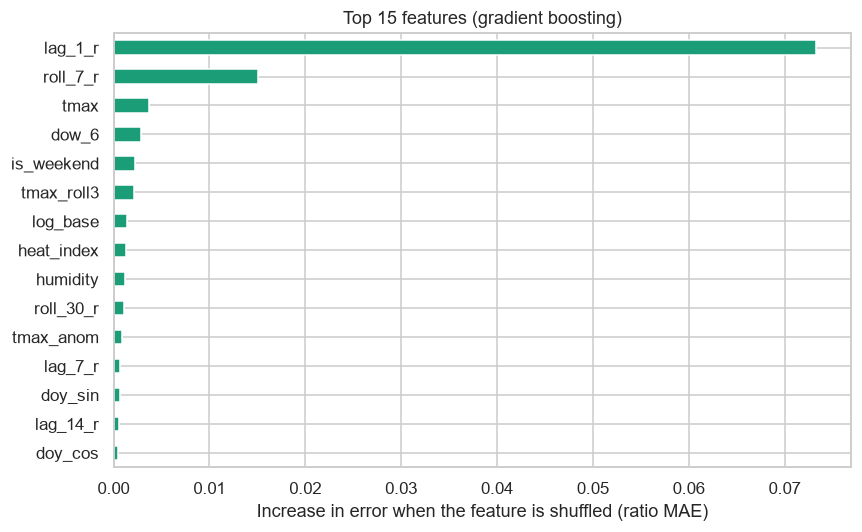

In [29]:
sample = test.sample(4000, random_state = 0)
perm = permutation_importance(models["Gradient Boosting"], sample[FEATURES], sample["y"],
                             n_repeats = 3, random_state = 0, scoring = "neg_mean_absolute_error")
importance = pd.Series(perm.importances_mean, index = FEATURES).sort_values(ascending = False).head(15)

fig, ax = plt.subplots(figsize = (8, 5))
importance.iloc[::-1].plot(kind = "barh", ax = ax, color = "#1b9e77")
ax.set_xlabel("Increase in error when the feature is shuffled (ratio MAE)")
ax.set_title("Top 15 features (gradient boosting)")
plt.tight_layout()
plt.show()

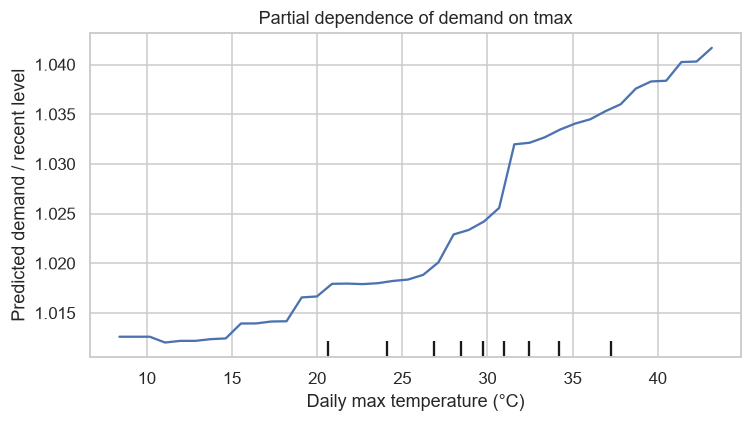

In [30]:
fig, ax = plt.subplots(figsize = (7, 4))
disp = PartialDependenceDisplay.from_estimator(models["Gradient Boosting"], sample[FEATURES], ["tmax"],
                                              kind = "average", method = "brute", percentiles = (0.01, 0.99),
                                              grid_resolution = 40, ax = ax)

disp.axes_[0, 0].set_xlabel("Daily max temperature (°C)")
disp.axes_[0, 0].set_ylabel("Predicted demand / recent level")
ax.set_title("Partial dependence of demand on tmax")
plt.tight_layout()
plt.show()

In [31]:
# Save test predictions for Part 3 (financial impact)
out = test[["state", "date", "peak_demand_mw", "base", "tmax", "hot_day"]].copy()
out["pred_best_mw"] = preds[best_name]
out["pred_persistence_mw"] = preds["Persistence (lag 1)"]
out.to_csv(PROCESSED_DIR / "test_predictions.csv", index=False)
print("Saved", len(out), "rows | best model:", best_name)

Saved 13552 rows | best model: Neural Network (MLP)


## Takeaways from Part 2
**Best model vs. persistence:** All four models beat the persistence baseline (copy yesterday's demand) on the held-out test period (Jan 2023 to Apr 2024). The neural network scored best, with a WAPE of 3.04% against 3.81% for persistence, about 20% less error (MAE 221 MW vs. 277 MW). Gradient boosting (3.17%), Random Forest (3.31%) and Ridge (3.56%) reduced error by about 17%, 13% and 7%. The top three models are within roughly 0.3 percentage points of each other, so I treat them as roughly tied. The "same day last week" rule was far worse than persistence (7.18%).

**Limitations**
- The model uses **actual** same-day weather. A real day-ahead forecast would use *forecast* weather, which is less accurate, so these scores are optimistic.
- The test period holds one full summer (2023) plus Jan to Apr 2024, so heatwave conclusions rest on limited extreme-heat days.
- One random seed and light tuning; differences of a few hundredths of a percentage point between models are not meaningful.
- No holiday or festival calendar, and no rainfall or wind.

# Part 3. Financial Impact

Part 2 measured forecast accuracy in percentages. Part 3 translates that into rupees and asks three questions:
1. What does forecast error cost, and how much does the model save compared with simply copying yesterday's demand?
2. Under-forecasting and over-forecasting cost different amounts. Can a deliberate safety margin cut the bill further?
3. How much extra demand, and extra cost, would a hotter summer add?

The dataset holds peak demand in MW but no prices, no hourly demand profile and no contract details, so the conversion to rupees rests on stated assumptions. The *comparisons* (model vs. baseline, with vs. without a margin) are more trustworthy than the absolute rupee figures, and a sensitivity grid shows how much the conclusions depend on the assumptions.

## 13. How forecast error becomes money
A utility buys most of its energy a day ahead, based on demand forecast
- **Under-forecast** (forecast below actual demand): the missing energy must be bought at short notice at a higher price.
- **Over-forecast** (forecast above actual demand): the surplus energy is resold below the price paid, a loss.

The data gives peak demand in **MW**, but money is paid per **MWh**. We bridge this by assuming the peak-time error lasts a fixed number of hours each day.

`daily cost = (under-forecast MW × under-forecast cost + over-forecast MW × over-forecast cost) × peak hours`

| assumption | value | basis |
|---|---|---|
| Planned (day-ahead) price | Rs 7,100 per MWh | Average day-ahead exchange price was about Rs 7.14/kWh in 2023 and Rs 7.20/kWh in Jan to Jun 2024 (CERC market data, [PXIL comparison table](https://cercind.gov.in/2025/draft_reg/Comments_8-SM-2024/PXIL.pdf)) |
| Top-up price for a shortfall | Rs 10,000 per MWh | Exchange price ceiling of Rs 10/kWh for most market segments from April 2023 ([CERC order 5/SM/2023](https://cercind.gov.in/2023/orders/5-SM-2023.pdf)); it was Rs 12/kWh before that, and an upper-end figure |
| Loss on resold surplus | 25% of the planned price | **Assumption, not sourced** |
| Peak hours per day | 4 hours | **Assumption, not sourced** (converts MW at peak into MWh) |

So an under-forecast costs the *extra* Rs 2,900 per MWh (10,000 minus 7,100) and an over-forecast costs Rs 1,775 per MWh (25% of 7,100). Not modelled: load-shedding losses and deviation-settlement penalties, which can make shortfalls more expensive than assumed here. Edit the numbers in the next cell to test your own.

In [32]:
# -------- Financial Assumptions -------- 

PRICE_PLANNED = 7_100               # Rs per MWh, planned day-ahead energy (average exchange price, about Rs 7.1/kWh)
PRICE_SHORTFALL = 10_000            # Rs per MWh, unplanned top-up energy (exchange price ceiling, Rs 10/kWh)
SURPLUS_LOSS_SHARE = 0.25           # ASSUMPTION: share of the planned price lost when surplus is resold
PEAK_HOURS = 4                      # ASSUMPTION: hours per day the peak-time error is assumed to last

UNDER_COST = PRICE_SHORTFALL - PRICE_PLANNED           # Rs per MWh of under-forecast
OVER_COST = PRICE_PLANNED * SURPLUS_LOSS_SHARE         # Rs per MWh of over-forecast
CRORE = 1e7                                            # 1 crore = 10 million rupees
MODEL = "Gradient Boosting"                            # the model used for the scenario and margin analysis

def forecast_cost(actual_mw, pred_mw, under_cost = None, over_cost = None, hours = None):
    """Rupee cost of forecast errors, one value per row."""
    under_cost = UNDER_COST if under_cost is None else under_cost
    over_cost = OVER_COST if over_cost is None else over_cost
    hours = PEAK_HOURS if hours is None else hours

    under_mw = np.clip(actual_mw - pred_mw, 0, None)        #forecast too low
    over_mw = np.clip(pred_mw - actual_mw, 0, None)         # forecast too high
    return (under_mw * under_cost + over_mw * over_cost) * hours

print(f"Under-forecast cost: Rs {UNDER_COST:,.0f}/MWh | Over-forecast: Rs {OVER_COST:,.0f}/MWh")

Under-forecast cost: Rs 2,900/MWh | Over-forecast: Rs 1,775/MWh


In [33]:
print(forecast_cost(np.array([10000, 10000]), np.array([9800, 10300])) / CRORE)

[0.232 0.213]


## 14. What forecast error costs: model vs baselines
Every model's test-period forecasts are converted to a cost. The saving is measured against **persistence** (copy yesterday), the simple rule a utility could use with no model at all. The period covers 28 states over 16 months.

In [34]:
rows = {}
for name, pred in preds.items():
    under = np.clip(actual - pred, 0, None)
    over = np.clip(pred - actual, 0, None)
    rows[name] = {"under_forecast_cost_cr": (under * UNDER_COST * PEAK_HOURS).sum() / CRORE,
                 "over_forecast_cost_cr": (over * OVER_COST * PEAK_HOURS).sum() / CRORE}

cost_table = pd.DataFrame(rows).T
cost_table["total_cost_cr"] = cost_table["under_forecast_cost_cr"] + cost_table["over_forecast_cost_cr"]
persist_cost = cost_table.loc["Persistence (lag 1)", "total_cost_cr"]
cost_table["saving_vs_persistence_cr"] = persist_cost - cost_table["total_cost_cr"]
cost_table["saving_%"] = cost_table["saving_vs_persistence_cr"] / persist_cost * 100
cost_table = cost_table.sort_values("total_cost_cr")
cost_table.round(1)

,under_forecast_cost_cr,over_forecast_cost_cr,total_cost_cr,saving_vs_persistence_cr,saving_%
Neural Network (MLP),1585.3,1156.6,2741.9,770.8,21.9
Gradient Boosting,1920.5,1038.7,2959.2,553.5,15.8
Random Forest,1937.4,1127.0,3064.4,448.3,12.8
Ridge,2121.7,1186.0,3307.7,205.0,5.8
Persistence (lag 1),2188.8,1323.9,3512.7,0.0,0.0
Same day last week (lag 7),4205.8,2444.6,6650.5,-3137.8,-89.3


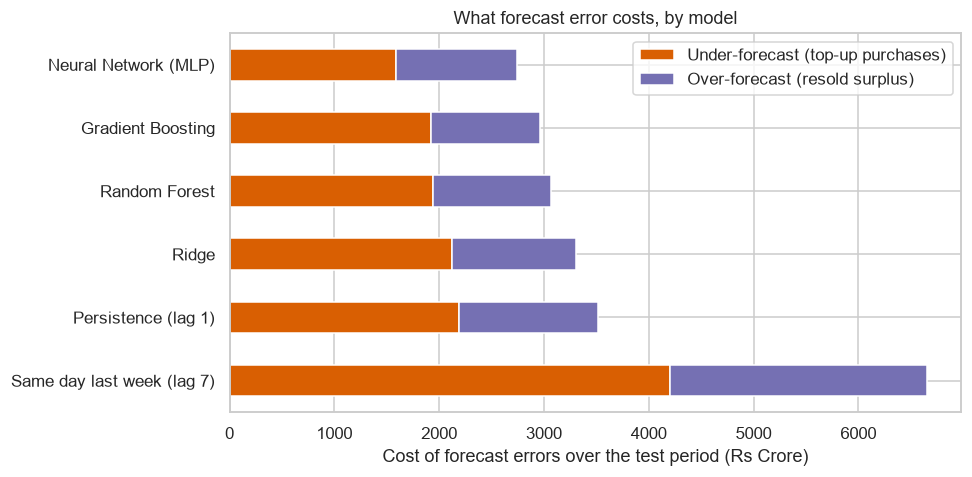

In [35]:
fig, ax = plt.subplots(figsize = (9, 4.5))
cost_table[["under_forecast_cost_cr", "over_forecast_cost_cr"]].plot(
    kind = "barh", stacked = True, ax = ax, color = ["#d95f02", "#7570b3"])
ax.invert_yaxis()
ax.set_xlabel("Cost of forecast errors over the test period (Rs Crore)")
ax.set_ylabel("")
ax.set_title("What forecast error costs, by model")
ax.legend(["Under-forecast (top-up purchases)", "Over-forecast (resold surplus)"])
plt.tight_layout()
plt.show()

### How sensitive is the saving to the price assumptions?
The two cost assumptions are the shakiest inputs, so we vary both. Each cell shows the model's saving over persistence (Rs crore) for one combination. If the numbers stay positive everywhere, the conclusion does not depend on getting the prices exactly right. The case used above is the middle cell.

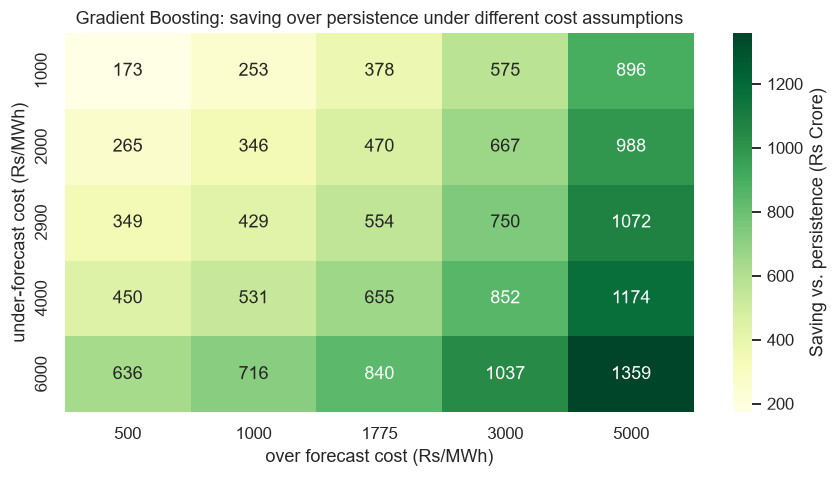

Smallest saving in the grid (Rs Crore): 172.9


In [36]:
under_grid = [1_000, 2_000, 2_900, 4_000, 6_000]       # Rs per MWh
over_grid = [500, 1_000, 1_775, 3_000, 5_000]          # Rs per MWh
persist = preds["Persistence (lag 1)"]
grid = pd.DataFrame(
    [[(forecast_cost(actual, persist, u, o) - forecast_cost(actual, preds[MODEL], u, o)).sum() / CRORE
     for o in over_grid] for u in under_grid],
    index = pd.Index(under_grid, name = "under-forecast cost (Rs/MWh)"),
    columns = pd.Index(over_grid, name = "over forecast cost (Rs/MWh)")
)

fig, ax = plt.subplots(figsize = (8, 4.5))
sb.heatmap(grid, annot = True, fmt = ".0f", cmap = "YlGn", cbar_kws = {"label": "Saving vs. persistence (Rs Crore)"}, ax = ax)
ax.set_title(f"{MODEL}: saving over persistence under different cost assumptions")
plt.tight_layout()
plt.show()
print("Smallest saving in the grid (Rs Crore):", round(grid.values.min(), 1))

## 15. A deliberate safety margin
Because a missed megawatt costs more than a spare one (Rs 2,900 vs. Rs 1,775 per MWh here), the cheapest forecast is not the most *accurate* one. It is slightly **high**. In plain terms, the forecast should aim at the point where roughly `under cost / (under cost + over cost)` of days would fall below it, here about 62%, not at the 50% midpoint.

We test this by multiplying the model's forecast by `1 + margin`. To avoid peeking at the test period, the margin is chosen on the **validation year**, using a model trained on the training years only, and then applied once to the test period.

Margin chosen on validation year: 1.5%


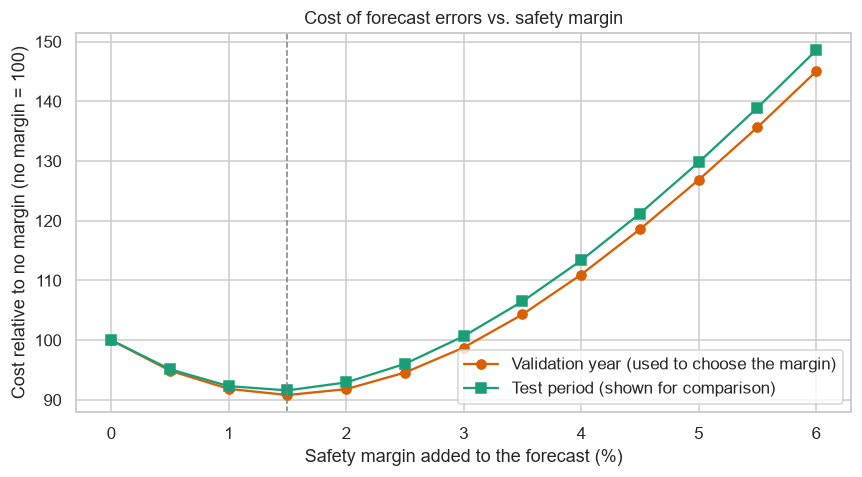

In [37]:
gb_train_only = HistGradientBoostingRegressor(max_iter = 300, random_state = RANDOM_STATE, **BEST_GB)
gb_train_only.fit(train_fit[FEATURES], train_fit["y"])
val_pred = gb_train_only.predict(val[FEATURES]) * val["base"].values
val_actual = val["peak_demand_mw"].values

margins = np.round(np.arange(0, 0.0601, 0.005), 3)
val_cost = np.array([forecast_cost(val_actual, val_pred * (1 + m)).sum() / CRORE for m in margins])
test_cost = np.array([forecast_cost(actual, preds[MODEL] * (1 + m)).sum() / CRORE for m in margins])
BEST_MARGIN = float(margins[int(np.argmin(val_cost))])
print(f"Margin chosen on validation year: {BEST_MARGIN:.1%}")

val_index = val_cost / val_cost[0] * 100                  #cost relative to no margin (= 100), so both periods share one axis
test_index = test_cost / test_cost[0] * 100

fig, ax = plt.subplots(figsize = (8, 4.5))
ax.plot(margins * 100, val_index, marker = "o", color = "#d95f02", label = "Validation year (used to choose the margin)")
ax.plot(margins * 100, test_index, marker = "s", color = "#1b9e77", label = "Test period (shown for comparison)")
ax.axvline(BEST_MARGIN * 100, color = "grey", ls = "--", lw = 1)
ax.set_xlabel("Safety margin added to the forecast (%)")
ax.set_ylabel("Cost relative to no margin (no margin = 100)")
ax.set_title("Cost of forecast errors vs. safety margin")
ax.legend()
plt.tight_layout()
plt.savefig("../images/safety_margin.png", dpi=150, bbox_inches="tight")
plt.show()

In [38]:
p_margin = preds[MODEL] * (1 + BEST_MARGIN)
compare_margin = pd.DataFrame({
    "cost (Rs crore)": [forecast_cost(actual, persist).sum() / CRORE,
                       forecast_cost(actual, preds[MODEL]).sum() / CRORE,
                       forecast_cost(actual, p_margin).sum() / CRORE],
    "WAPE (%)": [wape(actual, persist), wape(actual, preds[MODEL]), wape(actual, p_margin)],
    "days under-forecast (%)": [(persist < actual).mean() * 100, (preds[MODEL] < actual).mean() * 100,
                               (p_margin < actual).mean() * 100],
}, index = ["Persistence", MODEL, f"{MODEL} + {BEST_MARGIN:.1%} margin"])
compare_margin.round(2)

,cost (Rs crore),WAPE (%),days under-forecast (%)
Persistence,3512.71,3.81,51.65
Gradient Boosting,2959.17,3.17,54.52
Gradient Boosting + 1.5% margin,2710.32,3.26,37.69


The margin makes the forecast slightly *less accurate* (WAPE can rise) while making it *cheaper*, because it trades a few costly shortfalls for more of the cheap surplus. That is a business-driven choice, not a better model, and it only holds if shortfalls really are costlier than surpluses.

## 16. Heatwave scenario: what does a hotter summer add?
We ask the trained model to forecast the test period again with temperatures shifted up by 1 to 4°C, leaving everything else (calendar, demand history) unchanged. The extra demand is the difference from the normal forecast.

To keep the weather features consistent, the shift is applied to `tmax`, `tmin`, `heat_index`, `tmax_anom` and `tmax_roll3`, and the hot-day, hot-night and heatwave-streak features are recomputed from the shifted temperatures. The `heat_index` shift is an approximation, since its exact formula is not in the data.

In [39]:
SHIFT_COLS = ["tmax", "tmin", "heat_index", "tmax_anom", "tmax_roll3"]

def scenario_forecast(delta_c, model_name = MODEL):
    sc = panel[["state", "date"] + SHIFT_COLS].copy()
    sc[SHIFT_COLS] = sc[SHIFT_COLS] + delta_c
    sc["hot_day"] = (sc["tmax"] >= 40).astype(int)
    sc["hot_night"] = (sc["tmin"] >= 30).astype(int)
    sc["hot_streak"] = sc.groupby("state")["hot_day"].transform(streak)
    merged = test[["state", "date"]].merge(sc, on = ["state", "date"], how = "left")
    X = test[FEATURES].copy()
    for c in SHIFT_COLS + ["hot_day", "hot_night", "hot_streak"]:
        X[c] = merged[c].values
    return models[model_name].predict(X) * test["base"].values

# Sanity check: with no warning, the scenario must reproduce the normal forecast exactly
assert np.allclose(scenario_forecast(0), preds[MODEL]), "scenario pipeline does not match the normal forecast"
print("Sanity check passed: 0 degrees of warning reproduces the normal forecast")

Sanity check passed: 0 degrees of warning reproduces the normal forecast


In [40]:
normal = preds[MODEL]
rows = []
for d in [1, 2, 3, 4]:
    extra = scenario_forecast(d) - normal
    extra_mwh = extra[summer].sum() * PEAK_HOURS
    rows.append({"warming (C)": d,
                "extra demand, summer (%)": extra[summer].sum() / normal[summer].sum() * 100,
                "extra demand, hot days (%)": extra[hot].sum() / normal[hot].sum() * 100,
                "extra energy, summer (GWh)": extra_mwh / 1000,
                "cost at planned price (Rs crore)": extra_mwh * PRICE_PLANNED / CRORE,
                "cost at price ceiling (Rs crore)": extra_mwh * PRICE_SHORTFALL / CRORE})
scenario = pd.DataFrame(rows).set_index("warming (C)")
scenario.round(2)

,"extra demand, summer (%)","extra demand, hot days (%)","extra energy, summer (GWh)",cost at planned price (Rs crore),cost at price ceiling (Rs crore)
warming (C),,,,,
1,0.25,0.12,245.58,174.36,245.58
2,0.46,0.12,448.79,318.64,448.79
3,0.63,0.19,614.07,435.99,614.07
4,0.71,0.20,691.56,491.01,691.56


In [41]:
extra = scenario_forecast(2) - normal
print(extra[summer].sum() * PEAK_HOURS / 1000)

448.79327556184865


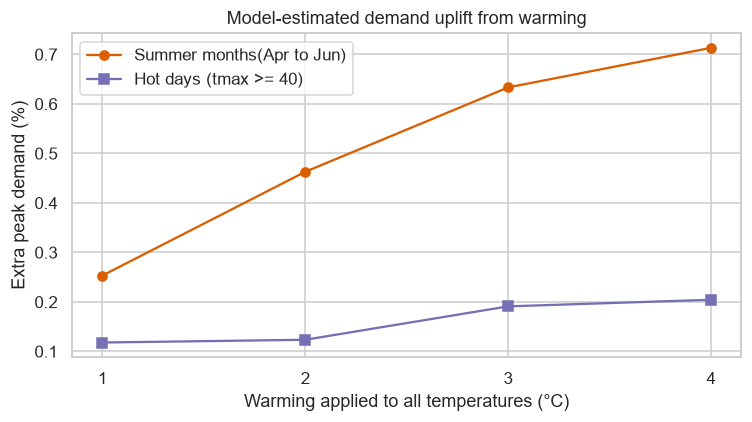

In [42]:
fig, ax = plt.subplots(figsize = (7, 4))
ax.plot(scenario.index, scenario["extra demand, summer (%)"], marker = "o", color = "#d95f02", label = "Summer months(Apr to Jun)")
ax.plot(scenario.index, scenario["extra demand, hot days (%)"], marker = "s", color = "#7570b3", label = "Hot days (tmax >= 40)")
ax.set_xlabel("Warming applied to all temperatures (°C)")
ax.set_ylabel("Extra peak demand (%)")
ax.set_xticks([1, 2, 3, 4])
ax.set_title("Model-estimated demand uplift from warming")
ax.legend()
plt.tight_layout()
plt.show()

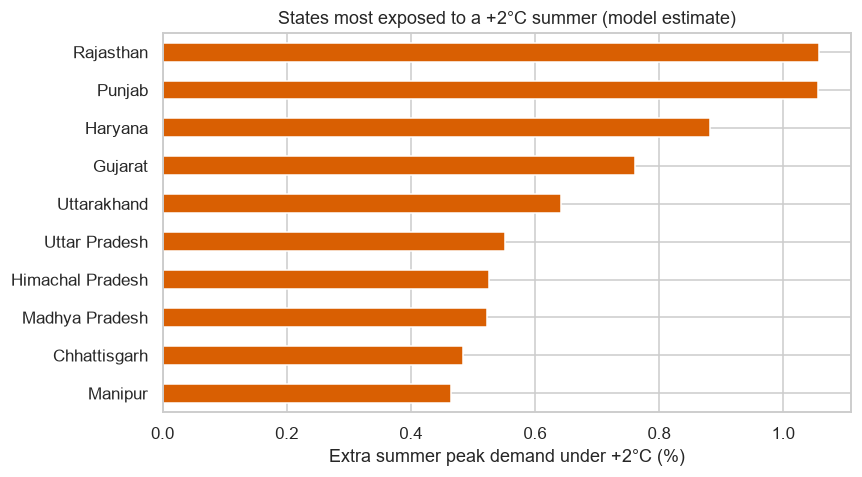

In [43]:
extra2 = scenario_forecast(2) - normal
by_state = (pd.DataFrame({"state": test["state"], "extra": extra2, "normal": normal})[summer]
           .groupby("state").sum())
by_state["uplift_%"] = by_state["extra"] / by_state["normal"] * 100
top = by_state["uplift_%"].sort_values(ascending = False).head(10)

fig, ax = plt.subplots(figsize = (8, 4.5))
top.iloc[::-1].plot(kind = "barh", ax = ax, color = "#d95f02")
ax.set_xlabel("Extra summer peak demand under +2°C (%)")
ax.set_ylabel("")
ax.set_title("States most exposed to a +2°C summer (model estimate)")
ax.set_yticklabels([s.title() for s in top.index[::-1]])
plt.tight_layout()
plt.show()

**Read the scenario with care.**
- The model learned from the historical relationship between temperature and demand. Beyond the temperatures it saw in training, tree-based models stay flat, so the estimate is more likely a **lower bound** than an exaggeration.
- Section 11 showed the average temperature response is modest (about 3% across the whole range), and the partial dependence plot probably understates it because correlated weather features were held fixed. The scenario shifts them together, so it is more realistic, but it still reflects only what the history contains.
- The scenario does not include rising air-conditioner ownership, supply limits, or any change in behaviour.
- The cost columns price the extra energy at the planned price (low case) and at the price ceiling (high case).

## 17. Summary and takeaways

In [44]:
model_row = cost_table.loc[MODEL]
margin_cost = forecast_cost(actual, p_margin).sum() / CRORE
extra2_mwh = extra2[summer].sum() * PEAK_HOURS

summary = pd.Series({
    "Cost of errors with persistence (Rs crore)": persist_cost,
    f"Cost of errors with {MODEL} (Rs crore)": model_row["total_cost_cr"],
    "Saving from the model (Rs crore)": model_row["saving_vs_persistence_cr"],
    "Saving from the model (%)": model_row["saving_%"],
    f"Cost with {BEST_MARGIN:.1%} safety margin (Rs crore)": margin_cost,
    "Additional saving from the margin (Rs crore)": model_row["total_cost_cr"] - margin_cost,
    "+2C summer: extra demand (%)": scenario.loc[2, "extra demand, summer (%)"],
    "+2C summer: extra energy (GWh)": extra2_mwh / 1000,
    "+2C summer: extra cost at planned price (Rs crore)": extra_mwh * PRICE_PLANNED / CRORE,
}, name = "value")
summary.round(2).to_frame()

,value
Cost of errors with persistence (Rs crore),3512.71
Cost of errors with Gradient Boosting (Rs crore),2959.17
Saving from the model (Rs crore),553.54
Saving from the model (%),15.76
Cost with 1.5% safety margin (Rs crore),2710.32
Additional saving from the margin (Rs crore),248.85
+2C summer: extra demand (%),0.46
+2C summer: extra energy (GWh),448.79
+2C summer: extra cost at planned price (Rs crore),491.01


## Takeaways from Part 3
**Cost of forecast error:** Under the stated price assumptions, gradient boosting's forecast errors cost about Rs 2,959 crore over the 16-month test period across 28 states, against Rs 3,513 crore for persistence: a saving of about Rs 554 crore (15.8%). The saving stays positive across the whole sensitivity grid of under- and over-forecast costs, ranging from about Rs 173 crore to about Rs 1,360 crore, because the model reduces both kinds of error. The absolute rupee amounts depend on assumptions (notably the 4 peak hours per day), so the comparison matters more than the totals.

**Limitations**
- The rupee figures rest on assumptions. Two are sourced to market data (planned price and price ceiling) and two are not (surplus loss and peak hours). Rely on the *comparisons* and the sensitivity grid, not the absolute totals.
- Peak MW is converted to energy with a fixed number of peak hours, which is a crude stand-in for a real hourly demand curve.
- Load-shedding losses, deviation penalties and long-term contracts are not modelled.
- The model uses actual same-day weather, so real forecast errors would be larger, and the savings smaller.
- The scenario is a statistical extrapolation from 2014 to 2024 history, not a physical or engineering model.